# Examen ICCD753 Recuperación de Información

## 1. Objetivo

Desarrollar un sistema de recuperación de información sobre un corpus asignado. El sistema deberá indexar los documentos, recuperar y ordenar resultados mediante TF-IDF con similitud coseno y BM25, y exponer la búsqueda como un servicio web publicado en internet.

Se evaluará el servicio enviando consultas desde un cliente (p.ej. Postman) y contrastando los resultados con los juicios de relevancia (*qrels*) del corpus.

## 2. Corpus asignado

Cada estudiante recibirá un conjunto de datos. Todos contienen documentos, consultas y qrels. Se utilizarán los identificadores originales de los documentos para que los resultados puedan evaluarse.

| Corpus | Documentos y consultas | Qrels |
| --- | --- | --- |
| NFCorpus | [BeIR/nfcorpus](https://huggingface.co/datasets/BeIR/nfcorpus) | [BeIR/nfcorpus-qrels](https://huggingface.co/datasets/BeIR/nfcorpus-qrels) |
| SciFact | [BeIR/scifact](https://huggingface.co/datasets/BeIR/scifact) | [BeIR/scifact-qrels](https://huggingface.co/datasets/BeIR/scifact-qrels) |

## 3. Requisitos del sistema

### 3.1. Preparación e indexación

El sistema deberá:

1. Cargar e indexar los documentos del corpus asignado.
2. Aplicar y documentar las decisiones de preprocesamiento: tokenización, normalización, eliminación de stopwords y stemming o lematización.
3. Construir un vocabulario y un índice invertido que permita recuperar documentos.
4. Conservar la relación entre cada documento indexado y su identificador original.

La unidad de evaluación será el documento original, porque los qrels relacionan consultas con identificadores de documentos. No se debe dividir el texto en fragmentos.

### 3.2. Modelos de recuperación

Para cualquier consulta de texto, el sistema deberá producir dos rankings independientes:

- TF-IDF con similitud coseno.
- BM25.

Cada ranking deberá ordenar los documentos por puntuación de relevancia y permitir solicitar los primeros `k` resultados.

### 3.3. Servicio web

El sistema deberá estar publicado en internet y ofrecer, como mínimo, los siguientes endpoints:

**Comprobación de disponibilidad**

```http
GET /health
```

**Búsqueda**

```http
POST /search
Content-Type: application/json
```

Ejemplo de solicitud:

```json
{
  "query": "texto de la consulta",
  "model": "bm25",
  "top_k": 10
}
```

El campo `model` deberá aceptar `bm25` y `tfidf`. Una respuesta tendrá esta estructura:

```json
{
  "model": "bm25",
  "results": [
    {
      "rank": 1,
      "document_id": "identificador_original",
      "score": 8.42,
      "title": "Título, si está disponible",
      "snippet": "Fragmento del documento recuperado"
    }
  ]
}
```

Los resultados deberán estar ordenados de mayor a menor puntuación, no contener documentos duplicados y respetar el valor solicitado de `top_k`. El servicio debe aceptar consultas que el estudiante no conozca de antemano.

## 4. Evaluación de la recuperación

Cada estudiante debe evaluar ambos modelos con consultas de la partición `test` y sus qrels. Presentará, como mínimo:

- Precision@10.
- Recall@10.
- NDCG@10.
- Una comparación de los resultados de TF-IDF y BM25.

En el Jupyter Notebook se deberá indicar qué consultas se utilizaron y permitir reproducir los cálculos. La evaluación del docente podrá utilizar otras consultas del mismo conjunto.

## 5. Prueba del docente

El docente accederá a la URL entregada y realizará solicitudes desde un cliente de web service para comprobar:

1. La disponibilidad del servicio.
2. El funcionamiento de TF-IDF y BM25.
3. El formato, orden y validez de los resultados.
4. La correspondencia de los `document_id` con el corpus y los qrels.
5. La respuesta ante consultas no incluidas en los ejemplos de entrega.

## 6. Entregables

Cada estudiante entregará:

1. La URL pública del servicio web, accesible durante el período de revisión.
2. El código en Jupyter Notebook con los resultados de la ejecución de cada bloque de código, incluyendo los resultados de las métricas de evaluación de los modelos de recuperación.

Se evaluará que ambos modelos funcionen correctamente y que cada estudiante interprete sus resultados.

## 1. Carga y exploración del corpus

En esta fase se cargan los tres componentes del corpus **SciFact** (BEIR):

- **Documentos** (`BeIR/scifact`, configuración `corpus`): resúmenes científicos con `_id`, `title` y `text`.
- **Consultas** (`BeIR/scifact`, configuración `queries`): afirmaciones científicas (*claims*).
- **Juicios de relevancia** (`BeIR/scifact-qrels`, partición `test`): pares `(query-id, corpus-id, score)`.

**Decisiones:**

1. Se usa `datasets.load_dataset`, que se verificó que funciona con estos repositorios (publicados en formato parquet, sin script de carga). Como respaldo, si fallara (p. ej. por la retirada de los scripts de carga en `datasets>=4`), se descargan directamente los ficheros parquet de la rama `refs/convert/parquet` con `huggingface_hub`.
2. Todos los identificadores se tratan como **`str`**. En los qrels vienen como `int64`, mientras que en el corpus son cadenas; si no se unifican, la evaluación no encontraría coincidencias.
3. La unidad de recuperación es el **documento completo** (título + resumen), sin dividirlo en fragmentos, porque los qrels relacionan consultas con identificadores de documento.

In [1]:
# Imports de la fase 1
import json
import pandas as pd
import matplotlib.pyplot as plt

def cargar_scifact():
    """Devuelve (corpus, queries, qrels_test) como DataFrames de pandas.

    Primero intenta con `datasets.load_dataset`; si falla, descarga los parquet
    de la rama refs/convert/parquet con huggingface_hub.
    """
    try:
        from datasets import load_dataset
        corpus  = load_dataset("BeIR/scifact", "corpus")["corpus"].to_pandas()
        queries = load_dataset("BeIR/scifact", "queries")["queries"].to_pandas()
        qrels   = load_dataset("BeIR/scifact-qrels")["test"].to_pandas()
        metodo = "datasets.load_dataset"
    except Exception as e:
        print("load_dataset falló:", type(e).__name__, e)
        from huggingface_hub import hf_hub_download
        def parquet(repo, fichero):
            ruta = hf_hub_download(repo, fichero, repo_type="dataset",
                                   revision="refs/convert/parquet")
            return pd.read_parquet(ruta)
        corpus  = parquet("BeIR/scifact", "corpus/corpus/0000.parquet")
        queries = parquet("BeIR/scifact", "queries/queries/0000.parquet")
        qrels   = parquet("BeIR/scifact-qrels", "default/test/0000.parquet")
        metodo = "huggingface_hub (parquet)"
    print("Método de carga utilizado:", metodo)
    return corpus, queries, qrels

corpus_df, queries_df, qrels_test = cargar_scifact()

# Unificar identificadores como str (en los qrels vienen como int64)
corpus_df["_id"]  = corpus_df["_id"].astype(str)
queries_df["_id"] = queries_df["_id"].astype(str)
qrels_test["query-id"]  = qrels_test["query-id"].astype(str)
qrels_test["corpus-id"] = qrels_test["corpus-id"].astype(str)

# Valores nulos -> cadena vacía para trabajar siempre con texto
corpus_df[["title", "text"]] = corpus_df[["title", "text"]].fillna("")

print("Columnas corpus :", list(corpus_df.columns))
print("Columnas queries:", list(queries_df.columns))
print("Columnas qrels  :", list(qrels_test.columns))
corpus_df.head(3)

Método de carga utilizado: datasets.load_dataset
Columnas corpus : ['_id', 'title', 'text']
Columnas queries: ['_id', 'title', 'text']
Columnas qrels  : ['query-id', 'corpus-id', 'score']


,_id,title,text
0,4983,Microstructural development of human newborn c...,Alterations of the architecture of cerebral wh...
1,5836,Induction of myelodysplasia by myeloid-derived...,Myelodysplastic syndromes (MDS) are age-depend...
2,7912,"BC1 RNA, the transcript from a master gene for...",ID elements are short interspersed elements (S...


### 1.1. Estadísticas generales

Se cuentan documentos, consultas (totales y de test) y pares de qrels, y se comprueba la integridad: identificadores únicos, de tipo `str`, y que todos los documentos y consultas citados en los qrels existan en el corpus y en el fichero de consultas. Las **consultas de test** son las que aparecen en los qrels de la partición `test`.

In [2]:
# Conjunto de consultas de test = las que tienen juicios en qrels/test
test_qids = set(qrels_test["query-id"])

print(f"Documentos en el corpus        : {len(corpus_df)}")
print(f"Consultas totales              : {len(queries_df)}")
print(f"Consultas de test (con qrels)  : {len(test_qids)}")
print(f"Pares (query, doc) en qrels    : {len(qrels_test)}")
print(f"Valores de score en qrels      : {sorted(qrels_test['score'].unique().tolist())}")

# Integridad de identificadores
print()
print("¿_id de documentos únicos?           ", corpus_df["_id"].is_unique)
print("¿_id de documentos son str?          ", corpus_df["_id"].map(type).eq(str).all())
print("¿corpus-id de qrels son str?         ", qrels_test["corpus-id"].map(type).eq(str).all())
print("¿Todos los corpus-id están en corpus?", set(qrels_test["corpus-id"]) <= set(corpus_df["_id"]))
print("¿Todas las query-id test en queries? ", test_qids <= set(queries_df["_id"]))
print("Ejemplos de _id:", corpus_df["_id"].head(5).tolist())

Documentos en el corpus        : 5183
Consultas totales              : 1109
Consultas de test (con qrels)  : 300
Pares (query, doc) en qrels    : 339
Valores de score en qrels      : [1]

¿_id de documentos únicos?            True
¿_id de documentos son str?           True
¿corpus-id de qrels son str?          True
¿Todos los corpus-id están en corpus? True
¿Todas las query-id test en queries?  True
Ejemplos de _id: ['4983', '5836', '7912', '18670', '19238']


### 1.2. Documentos relevantes por consulta

Distribución del número de documentos relevantes por consulta de test. Si la mayoría de consultas tiene muy pocos relevantes, Precision@10 queda acotada superiormente (con 1 relevante, P@10 ≤ 0,1), por lo que Recall@10 y NDCG@10 serán más informativas.

In [3]:
rel_por_query = qrels_test.groupby("query-id").size()
print(rel_por_query.describe().round(2))
print()
print("Nº de consultas según cuántos relevantes tienen:")
print(rel_por_query.value_counts().sort_index().rename_axis("relevantes").rename("consultas"))

count    300.00
mean       1.13
std        0.53
min        1.00
25%        1.00
50%        1.00
75%        1.00
max        5.00
dtype: float64

Nº de consultas según cuántos relevantes tienen:
relevantes
1    277
2     14
3      4
4      3
5      2
Name: consultas, dtype: int64


### 1.3. Longitud de los documentos y títulos vacíos

La longitud se mide en palabras separadas por espacios (todavía sin preprocesar) sobre `title + text`, que es el texto que se indexará. Interesa porque BM25 normaliza por la longitud del documento respecto a la media (`avgdl`).

count    5183.0
mean      214.6
std        87.3
min        33.0
25%       158.0
50%       204.0
75%       260.0
max      1541.0
dtype: float64

Documentos sin título: 0
Documentos sin texto : 0


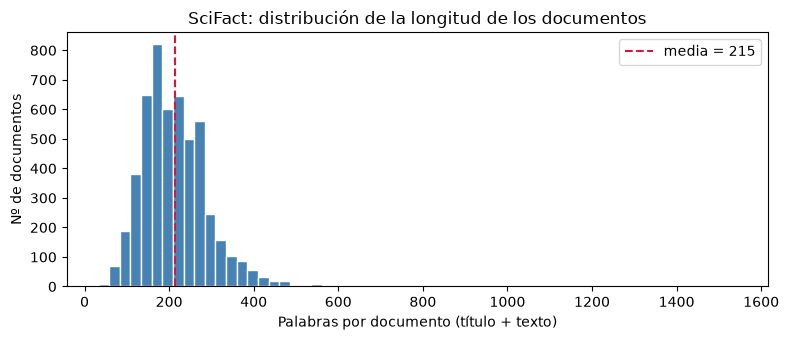

In [4]:
# Longitud en palabras (split por espacios) del texto que se indexará
long_docs = (corpus_df["title"] + " " + corpus_df["text"]).str.split().str.len()
print(long_docs.describe().round(1))

sin_titulo = (corpus_df["title"].str.strip() == "").sum()
sin_texto  = (corpus_df["text"].str.strip() == "").sum()
print(f"\nDocumentos sin título: {sin_titulo}")
print(f"Documentos sin texto : {sin_texto}")

# Histograma de longitudes
plt.figure(figsize=(8, 3.5))
plt.hist(long_docs, bins=60, color="steelblue", edgecolor="white")
plt.axvline(long_docs.mean(), color="crimson", ls="--", label=f"media = {long_docs.mean():.0f}")
plt.xlabel("Palabras por documento (título + texto)")
plt.ylabel("Nº de documentos")
plt.title("SciFact: distribución de la longitud de los documentos")
plt.legend()
plt.tight_layout()
plt.show()

### 1.4. Ejemplos de consultas con sus documentos relevantes

Se muestran dos consultas de test con sus documentos relevantes según los qrels, para ver qué tipo de correspondencia léxica existe entre la afirmación y el resumen.

In [5]:
docs_by_id = corpus_df.set_index("_id")
queries_by_id = queries_df.set_index("_id")

for qid in sorted(test_qids, key=int)[:2]:
    print(f"Query {qid}: {queries_by_id.loc[qid, 'text']}")
    for did in qrels_test.loc[qrels_test["query-id"] == qid, "corpus-id"]:
        d = docs_by_id.loc[did]
        print(f"   -> doc {did} | {d['title']}")
        print(f"      {d['text'][:250]}...")
    print()

Query 1: 0-dimensional biomaterials show inductive properties.
   -> doc 31715818 | New opportunities: the use of nanotechnologies to manipulate and track stem cells.
      Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo tracking; nanoparticles, carbon nanotub...

Query 3: 1,000 genomes project enables mapping of genetic sequence variation consisting of rare variants with larger penetrance effects than common variants.
   -> doc 14717500 | Rare Variants Create Synthetic Genome-Wide Associations
      Genome-wide association studies (GWAS) have now identified at least 2,000 common variants that appear associated with common diseases or related traits (http://www.genome.gov/gwastudies), hundreds of which have been convincingly replicated. It is gen...



### 1.5. Guardar el corpus

Se guarda **solo** `corpus.jsonl` en la raíz del proyecto (una línea JSON por documento con `_id`, `title`, `text`), que es lo que el servicio web cargará al arrancar. Las consultas y qrels de test no se guardan: se vuelven a cargar en el notebook cuando se necesiten para la evaluación.

In [6]:
with open("corpus.jsonl", "w", encoding="utf-8", newline="\n") as f:
    for _id, title, text in corpus_df[["_id", "title", "text"]].itertuples(index=False):
        f.write(json.dumps({"_id": _id, "title": title, "text": text},
                           ensure_ascii=False) + "\n")

# Verificación: releer y comprobar número de líneas e ids
with open("corpus.jsonl", encoding="utf-8") as f:
    lineas = [json.loads(l) for l in f]
print("Documentos guardados:", len(lineas))
print("Primer registro:", {k: v[:60] for k, v in lineas[0].items()})
print("¿ids idénticos al corpus?", [d["_id"] for d in lineas] == corpus_df["_id"].tolist())

Documentos guardados: 5183
Primer registro: {'_id': '4983', 'title': 'Microstructural development of human newborn cerebral white ', 'text': 'Alterations of the architecture of cerebral white matter in '}
¿ids idénticos al corpus? True


## 2. Preprocesamiento e índice invertido

Todo el código del sistema vive en un único fichero, `app.py`, generado desde este notebook con `%%writefile`. En esta fase se escribe su primera parte (imports, `STOPWORDS`, `preprocess` e `InvertedIndex`); las fases siguientes le **añaden** código con `%%writefile -a`.

### Decisiones de preprocesamiento

El mismo `preprocess` se aplica a documentos y consultas, para que ambos se representen en el mismo espacio de términos.

| Paso | Decisión | Justificación |
|---|---|---|
| 1. Minúsculas | `text.lower()` | "Cancer" y "cancer" deben ser el mismo término. |
| 2. Letras griegas | `α→alpha`, `β→beta`, `κ→kappa`, `μ/µ→mu`… | En biomedicina conviven "TNF-α" y "TNF-alpha", "NF-κB" y "NF-kappaB". Sin este mapeo la letra griega se perdería (no es `[a-z0-9]`). |
| 3. Normalización Unicode | NFKD y eliminación de marcas combinantes | Quita acentos y diacríticos ("Café"→"cafe", "naïve"→"naive") y unifica caracteres compatibles. |
| 4. Números | Se eliminan las comas de miles (`1,000`→`1000`); los tokens con dígitos se conservan | En SciFact los números y códigos son muy informativos: genes y proteínas (`p53`, `cd4`, `brca1`), cifras de las afirmaciones ("1,000 genomes"). |
| 5. Tokenización | Regex `[a-z0-9]+(?:-[a-z0-9]+)*` | Alfanumérica; cualquier otro símbolo separa tokens. Los guiones *internos* se capturan para tratarlos aparte. |
| 6. Guiones | Un compuesto genera la **forma unida y sus partes**: `il-6` → `il6`, `il`, `6`; `cell-free` → `cellfree`, `cell`, `free` | Los nombres biomédicos se escriben con y sin guion ("IL-6", "IL6"). La forma unida empareja ambas grafías y las partes permiten emparejar "cell free" o la palabra suelta. El coste es un ligero aumento de la longitud de los documentos con guiones, igual para todos. |
| 7. Stopwords | Lista inglesa de NLTK embebida como literal (sin `nltk.download`) + descarte de tokens de 1 carácter | Palabras funcionales sin poder discriminativo. Los tokens de 1 carácter (`6`, `t` de `t-cell`) son ruido; su información se conserva en la forma unida (`il6`, `tcell`). |
| 8. Stemming | Porter (`nltk.stem.PorterStemmer`), con caché | Agrupa variantes morfológicas ("inhibits", "inhibition", "inhibited"→"inhibit"). Se prefiere stemming a lematización porque no necesita etiquetado POS ni recursos descargables y, para un modelo léxico, mejora la cobertura de la consulta. |

**Texto indexado:** `título + " " + texto` de cada documento completo (sin chunking).

### Estructura del índice invertido

- `vocab`: término → `term_id`; `terms`: lista inversa.
- `postings[term_id] = (doc_idx, tf)`: dos arrays NumPy `int32` alineados y ordenados por `doc_idx`. Los arrays permiten calcular las puntuaciones de forma vectorizada en la fase 3.
- `df[term_id]`, `doc_len[doc_idx]` (en tokens preprocesados), `avgdl` y `N`: todo lo que necesitan TF-IDF y BM25.
- `doc_ids[doc_idx]`: el `_id` **original** (str) de cada documento, que es lo que devuelve el servicio y lo que se compara con los qrels.
- `titles` y `texts`: para devolver el título y el *snippet* en los resultados.

In [7]:
%%writefile app.py
# =============================================================================
# app.py  -  GENERADO desde examen1bim.ipynb (no editar a mano)
# Sistema de recuperación léxico sobre BeIR/scifact: preprocesamiento,
# índice invertido, modelos TF-IDF (coseno) y BM25, y API FastAPI.
# =============================================================================
import json
import re
import unicodedata
from collections import Counter
from functools import lru_cache

import numpy as np
from nltk.stem import PorterStemmer

# -----------------------------------------------------------------------------
# 1) Preprocesamiento
# -----------------------------------------------------------------------------

# Stopwords inglesas (lista de NLTK embebida como literal: no requiere
# nltk.download). Se omiten las formas con apóstrofo ("don't"...), porque el
# tokenizador parte por el apóstrofo y nunca las produce.
STOPWORDS = frozenset("""
i me my myself we our ours ourselves you your yours yourself yourselves he him
his himself she her hers herself it its itself they them their theirs
themselves what which who whom this that these those am is are was were be been
being have has had having do does did doing a an the and but if or because as
until while of at by for with about against between into through during before
after above below to from up down in out on off over under again further then
once here there when where why how all any both each few more most other some
such no nor not only own same so than too very s t can will just don should now
d ll m o re ve y ain aren couldn didn doesn hadn hasn haven isn ma mightn mustn
needn shan shouldn wasn weren won wouldn
""".split())

# Letras griegas frecuentes en biomedicina -> nombre en inglés (TNF-α == TNF-alpha)
GREEK = {
    "α": "alpha", "β": "beta", "γ": "gamma", "δ": "delta",
    "ε": "epsilon", "ζ": "zeta", "η": "eta", "θ": "theta",
    "κ": "kappa", "λ": "lambda", "μ": "mu", "µ": "mu",
    "π": "pi", "σ": "sigma", "τ": "tau", "ω": "omega",
}
_GREEK_RE = re.compile("|".join(GREEK))
_THOUSANDS_RE = re.compile(r"(?<=\d),(?=\d{3}\b)")       # 1,000 -> 1000
_TOKEN_RE = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*")        # alfanumérico + guiones internos
MIN_LEN = 2                                                # descarta tokens de 1 carácter

_stemmer = PorterStemmer()


def normalize(text):
    """Minúsculas, griegas -> nombre, y quitar acentos/diacríticos (NFKD)."""
    text = text.lower()
    text = _GREEK_RE.sub(lambda m: GREEK[m.group(0)], text)
    text = unicodedata.normalize("NFKD", text)
    return "".join(ch for ch in text if not unicodedata.combining(ch))


def tokenize(text):
    """Tokeniza texto ya normalizado.

    Un token compuesto con guiones ("il-6", "cell-free") genera la forma unida
    ("il6", "cellfree") y además cada parte ("il", "6", "cell", "free").
    """
    text = _THOUSANDS_RE.sub("", text)
    tokens = []
    for tok in _TOKEN_RE.findall(text):
        if "-" in tok:
            parts = tok.split("-")
            tokens.append("".join(parts))
            tokens.extend(parts)
        else:
            tokens.append(tok)
    return tokens


def remove_stopwords(tokens):
    """Quita stopwords y tokens demasiado cortos."""
    return [t for t in tokens if len(t) >= MIN_LEN and t not in STOPWORDS]


@lru_cache(maxsize=None)
def stem(token):
    """Stemming Porter (cacheado: el vocabulario se repite mucho)."""
    return _stemmer.stem(token)


def preprocess(text):
    """Pipeline completo: normalize -> tokenize -> stopwords -> stem."""
    return [stem(t) for t in remove_stopwords(tokenize(normalize(text or "")))]


# -----------------------------------------------------------------------------
# 2) Índice invertido
# -----------------------------------------------------------------------------

def load_corpus(path="corpus.jsonl"):
    """Lee corpus.jsonl (una línea JSON por documento: _id, title, text)."""
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


class InvertedIndex:
    """Índice invertido en memoria.

    Atributos tras build():
      doc_ids  list[str]   _id original del documento en la posición doc_idx
      N        int         nº de documentos
      vocab    dict        término -> term_id
      terms    list[str]   term_id -> término
      df       np.ndarray  df[term_id] = nº de documentos que contienen el término
      postings dict        term_id -> (doc_idx: np.int32[], tf: np.int32[]), doc_idx ascendente
      doc_len  np.ndarray  nº de tokens (preprocesados) de cada documento
      avgdl    float       longitud media de documento
      titles, texts list[str]  para construir títulos y snippets
    """

    def __init__(self):
        self.doc_ids, self.titles, self.texts = [], [], []
        self.vocab, self.terms, self.postings = {}, [], {}
        self.df = np.zeros(0, dtype=np.int32)
        self.doc_len = np.zeros(0, dtype=np.int32)
        self.N, self.avgdl = 0, 0.0

    def build(self, docs):
        """Construye el índice a partir de dicts con _id, title y text."""
        tmp_docs, tmp_tfs = {}, {}            # term_id -> listas temporales
        doc_len = []
        for doc_idx, d in enumerate(docs):
            _id = str(d["_id"])
            title, text = d.get("title") or "", d.get("text") or ""
            self.doc_ids.append(_id)
            self.titles.append(title)
            self.texts.append(text)
            tokens = preprocess(title + " " + text)   # texto indexado = título + texto
            doc_len.append(len(tokens))
            for term, tf in Counter(tokens).items():
                tid = self.vocab.get(term)
                if tid is None:
                    tid = self.vocab[term] = len(self.terms)
                    self.terms.append(term)
                    tmp_docs[tid], tmp_tfs[tid] = [], []
                tmp_docs[tid].append(doc_idx)
                tmp_tfs[tid].append(tf)

        if len(set(self.doc_ids)) != len(self.doc_ids):
            raise ValueError("Hay _id de documento duplicados")

        # Listas -> arrays numpy (doc_idx ya sale ordenado por construcción)
        self.postings = {tid: (np.asarray(tmp_docs[tid], dtype=np.int32),
                               np.asarray(tmp_tfs[tid], dtype=np.int32))
                         for tid in tmp_docs}
        self.df = np.array([len(self.postings[t][0]) for t in range(len(self.terms))],
                           dtype=np.int32)
        self.doc_len = np.asarray(doc_len, dtype=np.int32)
        self.N = len(self.doc_ids)
        self.avgdl = float(self.doc_len.mean()) if self.N else 0.0
        return self

    def get_postings(self, term):
        """Postings de un término YA preprocesado; arrays vacíos si no existe."""
        tid = self.vocab.get(term)
        if tid is None:
            return np.zeros(0, dtype=np.int32), np.zeros(0, dtype=np.int32)
        return self.postings[tid]


Writing app.py


### 2.1. Importar `app` y construir el índice

Se importa (y recarga con `importlib.reload`, por si `app.py` cambió en esta misma sesión del kernel) el módulo generado, se lee `corpus.jsonl` y se construye el índice midiendo el tiempo.

In [8]:
import importlib, time
import app
importlib.reload(app)

docs = app.load_corpus("corpus.jsonl")

t0 = time.perf_counter()
index = app.InvertedIndex().build(docs)
t_build = time.perf_counter() - t0
print(f"Índice construido en {t_build:.2f} s para {index.N} documentos")

Índice construido en 3.22 s para 5183 documentos


### 2.2. El preprocesamiento paso a paso

Primero sobre casos especiales que motivan las decisiones (guiones, números, griegas, acentos) y después sobre el título y comienzo de un documento real del corpus.

In [9]:
def mostrar_pasos(texto):
    """Imprime el resultado de cada paso del pipeline de preprocesamiento."""
    paso1 = app.normalize(texto)
    paso2 = app.tokenize(paso1)
    paso3 = app.remove_stopwords(paso2)
    paso4 = [app.stem(t) for t in paso3]
    assert paso4 == app.preprocess(texto)          # coincide con el pipeline real
    print("Original              :", texto)
    print("1) normalize          :", paso1)
    print("2) tokenize           :", paso2)
    print("3) stopwords + len>=2 :", paso3)
    print("4) Porter stem        :", paso4)
    print()

# Casos especiales
for caso in ["IL-6 and IL6 levels", "p53 mutations in CD4+ T-cells",
             "TNF-\u03b1 inhibits NF-\u03baB", "The 1,000 Genomes Project", "Naïve café cells"]:
    print(caso, "->", app.preprocess(caso))
print()

# Documento real: el primero cuyo texto contiene un compuesto con guion y dígito
import re
d = next(d for d in docs if re.search(r"[A-Za-z]+-\d", d["text"]))
print("Documento", d["_id"])
mostrar_pasos(d["title"] + " " + d["text"][:300])

IL-6 and IL6 levels -> ['il6', 'il', 'il6', 'level']
p53 mutations in CD4+ T-cells -> ['p53', 'mutat', 'cd4', 'tcell', 'cell']
TNF-α inhibits NF-κB -> ['tnfalpha', 'tnf', 'alpha', 'inhibit', 'nfkappab', 'nf', 'kappab']
The 1,000 Genomes Project -> ['1000', 'genom', 'project']
Naïve café cells -> ['naiv', 'cafe', 'cell']

Documento 5836
Original              : Induction of myelodysplasia by myeloid-derived suppressor cells. Myelodysplastic syndromes (MDS) are age-dependent stem cell malignancies that share biological features of activated adaptive immune response and ineffective hematopoiesis. Here we report that myeloid-derived suppressor cells (MDSC), which are classically linked to immunosuppression, inflammation, a
1) normalize          : induction of myelodysplasia by myeloid-derived suppressor cells. myelodysplastic syndromes (mds) are age-dependent stem cell malignancies that share biological features of activated adaptive immune response and ineffective hematopoiesis. here we re

### 2.3. Verificación del índice

Comprobaciones de integridad: `N` coincide con el número de documentos del corpus, los `_id` son únicos y de tipo `str`, `df` coincide con la longitud de cada lista de postings y la suma de todas las `tf` es igual a la suma de longitudes de documento.

In [10]:
import numpy as np
import pandas as pd

print("N (documentos indexados)     :", index.N)
print("Documentos en corpus.jsonl   :", len(docs))
print("¿N == nº de documentos?      :", index.N == len(docs))
print("¿doc_ids únicos?             :", len(set(index.doc_ids)) == index.N)
print("¿doc_ids son str?            :", all(isinstance(x, str) for x in index.doc_ids))
print("¿doc_ids alineados con corpus:", index.doc_ids == [d["_id"] for d in docs])
print("Tamaño del vocabulario       :", len(index.vocab))
print("Longitud media (avgdl)       :", round(index.avgdl, 2), "tokens")
print("Longitud mín / máx           :", index.doc_len.min(), "/", index.doc_len.max())
print("Tiempo de construcción       :", f"{t_build:.2f} s")

# Consistencia interna
df_ok  = all(index.df[t] == len(index.postings[t][0]) for t in index.postings)
tf_ok  = sum(int(tf.sum()) for _, tf in index.postings.values()) == int(index.doc_len.sum())
ord_ok = all(np.all(np.diff(di) > 0) for di, _ in index.postings.values())
print("¿df == len(postings)?        :", df_ok)
print("¿Σ tf == Σ doc_len?          :", tf_ok)
print("¿postings ordenados y sin duplicados?:", ord_ok)

N (documentos indexados)     : 5183
Documentos en corpus.jsonl   : 5183
¿N == nº de documentos?      : True
¿doc_ids únicos?             : True
¿doc_ids son str?            : True
¿doc_ids alineados con corpus: True
Tamaño del vocabulario       : 37974
Longitud media (avgdl)       : 151.73 tokens
Longitud mín / máx           : 27 / 1004
Tiempo de construcción       : 3.22 s


¿df == len(postings)?        : True
¿Σ tf == Σ doc_len?          : True
¿postings ordenados y sin duplicados?: True


In [11]:
# 15 términos con mayor document frequency
top = np.argsort(-index.df)[:15]
pd.DataFrame({"término": [index.terms[t] for t in top],
              "df": index.df[top],
              "% docs": (100 * index.df[top] / index.N).round(1)})

,término,df,% docs
0,cell,2530,48.8
1,result,2372,45.8
2,studi,2213,42.7
3,use,2182,42.1
4,activ,1834,35.4
5,show,1578,30.4
6,associ,1537,29.7
7,increas,1529,29.5
8,express,1526,29.4
9,function,1507,29.1


In [12]:
# Postings de ejemplo: término "p53" (tras preprocesar la palabra)
termino = app.preprocess("p53")[0]
doc_idx, tf = index.get_postings(termino)
print(f"Término '{termino}' -> term_id={index.vocab[termino]}, df={len(doc_idx)}")
pd.DataFrame({"doc_idx": doc_idx[:10], "_id original": [index.doc_ids[i] for i in doc_idx[:10]],
              "tf": tf[:10], "título": [index.titles[i][:70] for i in doc_idx[:10]]})

Término 'p53' -> term_id=1996, df=92


,doc_idx,_id original,tf,título
0,41,238409,1,Mechanisms of Renal Cell Apoptosis Induced by ...
1,167,928281,1,Failure of cell cleavage induces senescence in...
2,206,1171121,6,Microvessel Density and Status of p53 Protein ...
3,476,2582169,5,Inhibition of HDM2 and activation of p53 by ri...
4,500,2701077,1,Hematopoietic stem cell quiescence promotes er...
5,693,3863543,1,Mesenchymal Inflammation Drives Genotoxic Stre...
6,790,4389394,14,Deubiquitination of p53 by HAUSP is an importa...
7,816,4414547,2,Mosaic PPM1D mutations are associated with pre...
8,865,4460880,3,Mesenchymal-endothelial-transition contributes...
9,902,4653837,1,MicroRNA-29 induces cellular senescence in agi...
